In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from catboost import CatBoostClassifier, Pool
import optuna
from optuna.samplers import TPESampler
from optuna.pruners import MedianPruner
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from sklearn.metrics import (f1_score, precision_score, recall_score,
                             roc_auc_score, average_precision_score)

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
# при необходимости: !pip install -q catboost shap optuna
SEED = 42

CFG = dict(
    source=os.getenv("SMURF_SOURCE", "postgres"),   
    csv_path=os.getenv("SMURF_CSV", "data_leak_df_problems.csv"),
    unranked="drop",            # 
    use_rank_features=False,      
    feature_set="full_raw",       
    smurf_z=1.5,                  
    smurf_max_tier=5,             
)

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Загрузка

In [2]:
# столбцы, которые добавлял старый препроцессинг (нужны только при чтении старого CSV)
OLD_DERIVED = ["Unnamed: 0", "rank_known", "anon", "tier", "dur_min", "hd_pm", "lh_pm",
               "kda_c", "farm_pos", "perf_z", "smurf", "calibration", "label_src"]

def load_raw(cfg):
    if cfg["source"] == "postgres":
        from sqlalchemy import create_engine
        engine = create_engine(os.environ["SOURCE_POSTGRES_DSN"])
        df = pd.read_sql("SELECT * FROM dota.match_players", engine)
    else:
        df = pd.read_csv(cfg["csv_path"])
        df = df.drop(columns=[c for c in OLD_DERIVED if c in df.columns])
    return df.drop(columns=[c for c in ["roles", "name"] if c in df.columns])

## 2. Препроцессинг без обучаемых статистик

Здесь только построчные и матчевые операции (ничего, что «видит» другие матчи), поэтому делать это до сплита безопасно.

In [3]:
ANON_IDS = [0, 4294967295]
ITEM_COLS = [f"item_{i}" for i in range(6)] + [f"backpack_{i}" for i in range(3)] + ["item_neutral"]
METRICS = ["gold_per_min", "xp_per_min", "hd_pm", "lh_pm", "kda_c"]

def engineer(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    # ранг: -1 и NaN = неизвестен
    df["rank"] = df["rank"].where(df["rank"].notna() & (df["rank"] != -1))
    df["rank_known"] = df["rank"].notna()
    df["calibration"] = (~df["rank_known"]).astype(int)
    df["tier"] = np.floor(df["rank"] / 10)

    # скрытые профили
    df["anon"] = df["account_id"].isin(ANON_IDS)

    # длительность матча (мин) и фильтр 15..90 минут, как в исходном коде
    df["dur_min"] = (df["gold"] + df["gold_spent"]) / df["gold_per_min"].replace(0, np.nan)
    df = df[df["dur_min"].between(15, 90)].copy()

    # метрики игрока, из которых строится perf_z
    df["hd_pm"] = df["hero_damage"] / df["dur_min"]
    df["lh_pm"] = df["last_hits"] / df["dur_min"]
    df["kda_c"] = df["kda"].clip(upper=15)
    df["farm_pos"] = (df.groupby(["match_id", "is_radiant"])["gold_per_min"]
                        .rank(ascending=False, method="first"))

    df[ITEM_COLS] = df[ITEM_COLS].fillna(-99)

    # группа для сплита: настоящие аккаунты — по account_id,
    # скрытые — уникальная группа на каждую строку (иначе одна группа на ~35% данных)
    uniq = "anon_" + df["match_id"].astype(str) + "_" +f["player_slot"].astype(str)
    df["group"] = np.where(df["anon"], uniq, df["account_id"].astype(str))
    return df d

## 3. Разметка смурфов (fit на train → transform на всё)

Правило осталось прежним: смурф = известный ранг, `tier <= smurf_max_tier` и `perf_z >= smurf_z`. Меняется только то, что эталоны (`mu`, `sd` по `tier × farm_pos`) оцениваются на train.

In [4]:
class SmurfLabeler:
    def __init__(self, smurf_z=1.5, smurf_max_tier=5):
        self.smurf_z, self.smurf_max_tier = smurf_z, smurf_max_tier

    def fit(self, df):
        ref = df[df["rank_known"]]
        g = ref.groupby(["tier", "farm_pos"])[METRICS]
        self.mu_ = g.mean()
        self.sd_ = g.std().replace(0, np.nan)
        return self

    def _perf_z(self, sub):
        key = pd.MultiIndex.from_arrays([sub["tier"].to_numpy(), sub["farm_pos"].to_numpy()],
                                        names=["tier", "farm_pos"])
        mu = self.mu_.reindex(key).to_numpy()
        sd = self.sd_.reindex(key).to_numpy()
        z = (sub[METRICS].to_numpy() - mu) / sd
        z[~np.isfinite(z)] = np.nan
        n = (~np.isnan(z)).sum(axis=1)
        return np.where(n > 0, np.nansum(z, axis=1) / np.maximum(n, 1), np.nan)

    def transform(self, df):
        df = df.copy()
        df["perf_z"] = np.nan
        m = df["rank_known"]
        df.loc[m, "perf_z"] = self._perf_z(df[m])
        df["smurf"] = (m & (df["tier"] <= self.smurf_max_tier)
                         & (df["perf_z"] >= self.smurf_z)).astype("int8")
        # ранг известен, но для (tier, farm_pos) нет эталона из train -> метка не определена
        df["label_ok"] = ~m | df["perf_z"].notna()
        return df


def group_split(df, seed=SEED, test_size=0.2, val_size=0.2):
    gss = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
    tr_i, te_i = next(gss.split(df, groups=df["group"]))
    tr, te = df.iloc[tr_i], df.iloc[te_i]
    gss = GroupShuffleSplit(n_splits=1, test_size=val_size, random_state=seed)
    a, b = next(gss.split(tr, groups=tr["group"]))
    tr, va = tr.iloc[a], tr.iloc[b]
    assert not set(tr["group"]) & set(va["group"]) | set(tr["group"]) & set(te["group"]) | set(va["group"]) & set(te["group"])
    return tr, va, te

## 4. Признаки

Из матрицы признаков убираются: идентификаторы, всё, что порождено разметкой (`perf_z`, `farm_pos`, `kda_c`, `hd_pm`, `lh_pm`, `dur_min`), служебные флаги и (по умолчанию) ранг.

`feature_set="no_label_inputs"` дополнительно убирает сырые величины, из которых считается `perf_z`. Это жёсткий тест: сколько сигнала остаётся, если модель **не видит** вход правила разметки.

In [5]:
ID_COLS       = ["match_id", "account_id", "player_slot", "group"]
LABEL_DERIVED = ["perf_z", "farm_pos", "kda_c", "hd_pm", "lh_pm", "dur_min", "smurf", "label_ok", "anon"]
RANK_COLS     = ["rank", "tier", "rank_known", "calibration"]
LABEL_INPUTS  = ["gold_per_min", "xp_per_min", "hero_damage", "last_hits",
                 "kills", "deaths", "assists", "kda", "gold", "gold_spent", "net_worth",
                 "level"]   # level ~ функция суммарного опыта, т.е. косвенно xp_per_min
CAT_FEATURES  = ["hero_id"]

def build_features(df, cfg):
    drop = ID_COLS + LABEL_DERIVED
    if not cfg["use_rank_features"]:
        drop += RANK_COLS
    if cfg["feature_set"] == "no_label_inputs":
        drop += LABEL_INPUTS
    X = df.drop(columns=[c for c in drop if c in df.columns]).copy()
    for c in X.select_dtypes("bool").columns:
        X[c] = X[c].astype(int)
    X["hero_id"] = X["hero_id"].astype(int)
    assert not X.select_dtypes("object").shape[1], "остались нечисловые столбцы"
    return X


def leak_check(X, y, thr=0.90, top=10):
    """ROC-AUC каждого признака по отдельности. Значения > thr — кандидаты в утечку."""
    res = {}
    for c in X.columns:
        a = roc_auc_score(y, X[c].astype(float).fillna(-999))
        res[c] = max(a, 1 - a)
    s = pd.Series(res).sort_values(ascending=False)
    flagged = s[s > thr]
    print(f"Одиночный AUC, топ-{top}:"); print(s.head(top).round(4).to_string())
    print("\n⚠ подозрительно сильные признаки:" if len(flagged) else "\n✔ признаков с AUC > %.2f нет" % thr,
          list(flagged.index) if len(flagged) else "")
    return s

## 5. Пайплайн, обучение, метрики (базовая модель)

In [6]:
BASE_PARAMS = dict(depth=6, learning_rate=0.05, iterations=1000)

def prepare(cfg):
    df = engineer(load_raw(cfg))
    if cfg["unranked"] == "drop":
        df = df[df["rank_known"]]
    train, val, test = group_split(df)
    lab = SmurfLabeler(cfg["smurf_z"], cfg["smurf_max_tier"]).fit(train)   # эталоны только по train
    parts = []
    for p in (train, val, test):
        p = lab.transform(p)
        parts.append(p[p["label_ok"]])
    return parts, lab


def make_data(cfg):
    """Подготовка данных один раз: сплит, разметка, признаки."""
    (train, val, test), lab = prepare(cfg)
    Xtr, Xva, Xte = (build_features(d, cfg) for d in (train, val, test))
    return dict(train=train, val=val, test=test, labeler=lab,
                Xtr=Xtr, Xva=Xva, Xte=Xte,
                ytr=train["smurf"], yva=val["smurf"], yte=test["smurf"],
                cats=[c for c in CAT_FEATURES if c in Xtr.columns])


def fit_catboost(params, Xtr, ytr, Xev, yev, cats, od_wait=100):
    m = CatBoostClassifier(eval_metric="PRAUC", od_type="Iter", od_wait=od_wait,
                           random_seed=SEED, verbose=0, cat_features=cats, **params)
    m.fit(Xtr, ytr, eval_set=(Xev, yev), use_best_model=True)
    return m


def best_f1_threshold(y, p):
    ts = np.linspace(0.02, 0.98, 97)
    return ts[int(np.argmax([f1_score(y, p >= t, zero_division=0) for t in ts]))]


def evaluate(y, p, thr):
    pred = (p >= thr).astype(int)
    return dict(f1=f1_score(y, pred, zero_division=0),
                precision=precision_score(y, pred, zero_division=0),
                recall=recall_score(y, pred),
                roc_auc=roc_auc_score(y, p),
                pr_auc=average_precision_score(y, p))


def bootstrap_ci(y, p, thr, n=500, seed=SEED):
    """95% доверительные интервалы PR-AUC и F1 на тесте (на ~160 смурфах разница в 0.03 — это шум)."""
    rng = np.random.RandomState(seed); y = np.asarray(y); p = np.asarray(p)
    pr, f1 = [], []
    for _ in range(n):
        i = rng.randint(0, len(y), len(y))
        if y[i].sum() == 0:
            continue
        pr.append(average_precision_score(y[i], p[i]))
        f1.append(f1_score(y[i], p[i] >= thr, zero_division=0))
    q = lambda a: "[%.3f; %.3f]" % tuple(np.percentile(a, [2.5, 97.5]))
    return q(pr), q(f1)


def run(cfg, params=None, data=None, verbose=True):
    d = data if data is not None else make_data(cfg)
    params = BASE_PARAMS if params is None else params
    Xtr, Xva, Xte = d["Xtr"], d["Xva"], d["Xte"]
    ytr, yva, yte = d["ytr"], d["yva"], d["yte"]

    if verbose:
        print({k: len(d[k]) for k in ("train", "val", "test")},
              "| доля смурфов train/val/test: %.3f%% / %.3f%% / %.3f%%" %
              tuple(100 * y.mean() for y in (ytr, yva, yte)))
        print("признаки:", list(Xtr.columns), "\n")
        leak_check(Xtr, ytr)

    model = fit_catboost(params, Xtr, ytr, Xva, yva, d["cats"])
    thr = best_f1_threshold(yva, model.predict_proba(Xva)[:, 1])    # порог только по val
    p = model.predict_proba(Xte)[:, 1]
    res = dict(evaluate(yte, p, thr), best_iter=model.get_best_iteration(),
               thr=round(thr, 2), n_test=len(yte), n_test_pos=int(yte.sum()))
    return dict(model=model, Xte=Xte, yte=yte, pte=p, thr=thr, metrics=res,
                labeler=d["labeler"], test=d["test"], Xtr=Xtr, data=d, params=params)

In [7]:
out_base = run(CFG)
pd.DataFrame([out_base["metrics"]]).round(4)

{'train': 26663, 'val': 6674, 'test': 8336} | доля смурфов train/val/test: 1.853% / 1.798% / 1.943%
признаки: ['hero_id', 'item_0', 'item_1', 'item_2', 'item_3', 'item_4', 'item_5', 'backpack_0', 'backpack_1', 'backpack_2', 'item_neutral', 'kills', 'deaths', 'assists', 'kda', 'gold', 'gold_per_min', 'xp_per_min', 'gold_spent', 'net_worth', 'hero_damage', 'tower_damage', 'hero_healing', 'level', 'last_hits', 'denies', 'is_radiant', 'win', 'aghanims_scepter', 'aghanims_shard'] 

Одиночный AUC, топ-10:
xp_per_min      0.9425
gold_per_min    0.9350
level           0.8940
net_worth       0.8699
gold_spent      0.8491
gold            0.7647
kda             0.7431
hero_damage     0.7110
win             0.6709
deaths          0.6651

⚠ подозрительно сильные признаки: ['xp_per_min', 'gold_per_min']


,f1,precision,recall,roc_auc,pr_auc,best_iter,thr,n_test,n_test_pos
0,0.4138,0.3871,0.4444,0.9635,0.3872,59,0.18,8336,162


## 6. Подбор гиперпараметров (Optuna)

Как устроено, чтобы не обмануть себя:

* **Целевая метрика — PR-AUC** (а не ROC-AUC и не F1): при ~2% смурфов она честно отражает качество ранжирования и не зависит от порога.
* **Кросс-валидация, а не один val.** `StratifiedGroupKFold` по `group` на train+val. Во val всего ~120 смурфов, один val-сплит переобучается под себя.
* **Тест не трогается** до самого конца. Порог F1 выбирается на val, как и раньше.
* **Базовые параметры подаются первым trial** — прирост считается в тех же фолдах.
* `MedianPruner` обрывает заведомо слабые конфигурации после первых фолдов.
* Ранняя остановка идёт по hold-out-фолду, поэтому CV-оценка немного оптимистична (одинаково для всех trial, так что сравнивать конфигурации можно).

In [8]:
N_TRIALS = int(os.getenv("N_TRIALS", 40))
TIMEOUT  = int(os.getenv("OPTUNA_TIMEOUT", 1200))     # сек, защита от слишком долгого подбора

data = make_data(CFG)
X_tv = pd.concat([data["Xtr"], data["Xva"]]).reset_index(drop=True)
y_tv = pd.concat([data["ytr"], data["yva"]]).reset_index(drop=True)
g_tv = pd.concat([data["train"]["group"], data["val"]["group"]]).reset_index(drop=True)
folds = list(StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED).split(X_tv, y_tv, g_tv))
print("фолды (размер / смурфов):", [(len(b), int(y_tv.iloc[b].sum())) for _, b in folds])

FIXED = dict(bootstrap_type="Bayesian", iterations=1500)     # bagging_temperature работает только с Bayesian

def to_params(d):
    return {**FIXED, **d}

def suggest_params(trial):
    return to_params(dict(
        depth=trial.suggest_int("depth", 4, 8),
        learning_rate=trial.suggest_float("learning_rate", 0.02, 0.2, log=True),
        l2_leaf_reg=trial.suggest_float("l2_leaf_reg", 1, 30, log=True),
        random_strength=trial.suggest_float("random_strength", 0.1, 10, log=True),
        bagging_temperature=trial.suggest_float("bagging_temperature", 0, 5),
        rsm=trial.suggest_float("rsm", 0.5, 1.0),
        border_count=trial.suggest_categorical("border_count", [64, 128, 254]),
        auto_class_weights=trial.suggest_categorical("auto_class_weights", [None, "SqrtBalanced", "Balanced"]),
    ))

def objective(trial):
    params = suggest_params(trial)
    scores, iters = [], []
    for k, (a, b) in enumerate(folds):
        m = fit_catboost(params, X_tv.iloc[a], y_tv.iloc[a], X_tv.iloc[b], y_tv.iloc[b],
                         data["cats"], od_wait=75)
        scores.append(average_precision_score(y_tv.iloc[b], m.predict_proba(X_tv.iloc[b])[:, 1]))
        iters.append(m.get_best_iteration())
        trial.report(float(np.mean(scores)), k)
        if trial.should_prune():
            raise optuna.TrialPruned()
    trial.set_user_attr("mean_best_iter", int(np.mean(iters)))
    return float(np.mean(scores))

def progress(study, trial):
    if trial.number % 5 == 0 or trial.number == 0:
        print(f"trial {trial.number:3d} | value={trial.value if trial.value is not None else float('nan'):.4f}"
              f" | best={study.best_value:.4f}")

study = optuna.create_study(direction="maximize", study_name="smurf_catboost",
                            sampler=TPESampler(seed=SEED),
                            pruner=MedianPruner(n_startup_trials=8, n_warmup_steps=1))
# первым trial — базовая конфигурация, чтобы сравнить с ней в тех же фолдах
study.enqueue_trial(dict(depth=6, learning_rate=0.05, l2_leaf_reg=3.0, random_strength=1.0,
                         bagging_temperature=1.0, rsm=1.0, border_count=254, auto_class_weights=None))
study.optimize(objective, n_trials=N_TRIALS, timeout=TIMEOUT, callbacks=[progress])

done = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
print(f"\nзавершено: {len(done)}, отсечено: {len(study.trials) - len(done)}")
print(f"CV PR-AUC базовой конфигурации: {study.trials[0].value:.4f}")
print(f"CV PR-AUC лучшей конфигурации:  {study.best_value:.4f}  (trial {study.best_trial.number})")
print("лучшие параметры:", study.best_params)
study.trials_dataframe().to_csv("optuna_trials.csv", index=False)

фолды (размер / смурфов): [(11113, 205), (11112, 204), (11112, 205)]


trial   0 | value=0.3739 | best=0.3739


trial   5 | value=0.3444 | best=0.3739


trial  10 | value=0.3828 | best=0.3828


trial  15 | value=0.3772 | best=0.3869


trial  20 | value=0.3840 | best=0.3869


trial  25 | value=0.3776 | best=0.3901

завершено: 20, отсечено: 6
CV PR-AUC базовой конфигурации: 0.3739
CV PR-AUC лучшей конфигурации:  0.3901  (trial 24)
лучшие параметры: {'depth': 4, 'learning_rate': 0.024856325057875408, 'l2_leaf_reg': 23.68628729192739, 'random_strength': 8.173353283643506, 'bagging_temperature': 2.1143222215710393, 'rsm': 0.7609089777994518, 'border_count': 254, 'auto_class_weights': 'SqrtBalanced'}


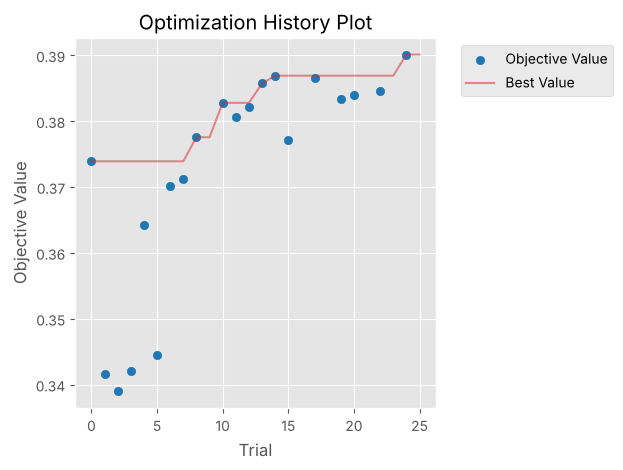

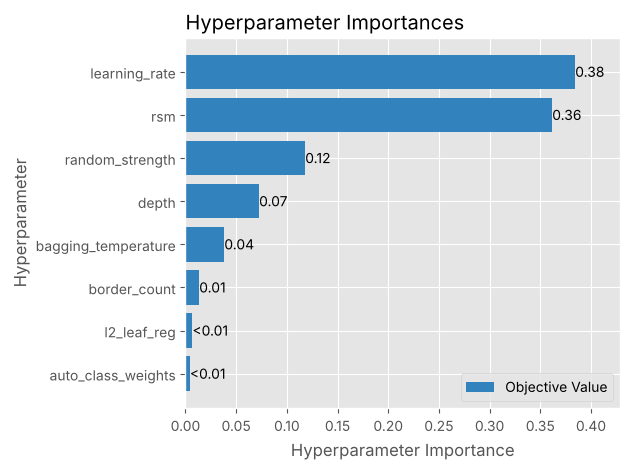

In [9]:
from optuna.visualization import matplotlib as optv
optv.plot_optimization_history(study); plt.tight_layout(); plt.show()
try:
    optv.plot_param_importances(study); plt.tight_layout(); plt.show()
except Exception as e:
    print("важность параметров не посчитана:", e)

### Финальная модель и честное сравнение на тесте

In [10]:
best_params = to_params(study.best_params)
out_tuned = run(CFG, params=best_params, data=data, verbose=False)

rows = {}
for name, o in {"baseline": out_base, "optuna": out_tuned}.items():
    pr_ci, f1_ci = bootstrap_ci(o["yte"], o["pte"], o["thr"])
    rows[name] = {**o["metrics"], "PR-AUC 95% CI": pr_ci, "F1 95% CI": f1_ci}
display(pd.DataFrame(rows).T.round(4))

# итоговая модель для SHAP ниже
out = out_tuned

,f1,precision,recall,roc_auc,pr_auc,best_iter,thr,n_test,n_test_pos,PR-AUC 95% CI,F1 95% CI
baseline,0.413793,0.387097,0.444444,0.96348,0.387234,59,0.18,8336,162,[0.315; 0.471],[0.346; 0.480]
optuna,0.343643,0.387597,0.308642,0.965324,0.387965,548,0.65,8336,162,[0.313; 0.472],[0.274; 0.407]


## 7. SHAP (для настроенной модели)

In [11]:
def catboost_shap(model, X):
    """Точные TreeSHAP-значения CatBoost (в лог-оддсах). Работают и с категориальным hero_id."""
    cats = [c for c in CAT_FEATURES if c in X.columns]
    sv = model.get_feature_importance(Pool(X, cat_features=cats), type="ShapValues")
    return sv[:, :-1], sv[:, -1]          # значения по признакам, базовое значение

model, Xte, yte, pte = out["model"], out["Xte"], out["yte"], out["pte"]

# выборка для графиков: все смурфы теста + случайные не-смурфы (отражено в подписи)
rng = np.random.RandomState(SEED)
pos = np.where(yte.to_numpy() == 1)[0]
neg = rng.choice(np.where(yte.to_numpy() == 0)[0], size=min(4000, (yte == 0).sum()), replace=False)
idx = np.concatenate([pos, neg])
Xs = Xte.iloc[idx]
sv, base = catboost_shap(model, Xs)
print(f"{len(pos)} смурфов + {len(neg)} случайных не-смурфов; графики — в лог-оддсах класса «смурф»")

162 смурфов + 4000 случайных не-смурфов; графики — в лог-оддсах класса «смурф»


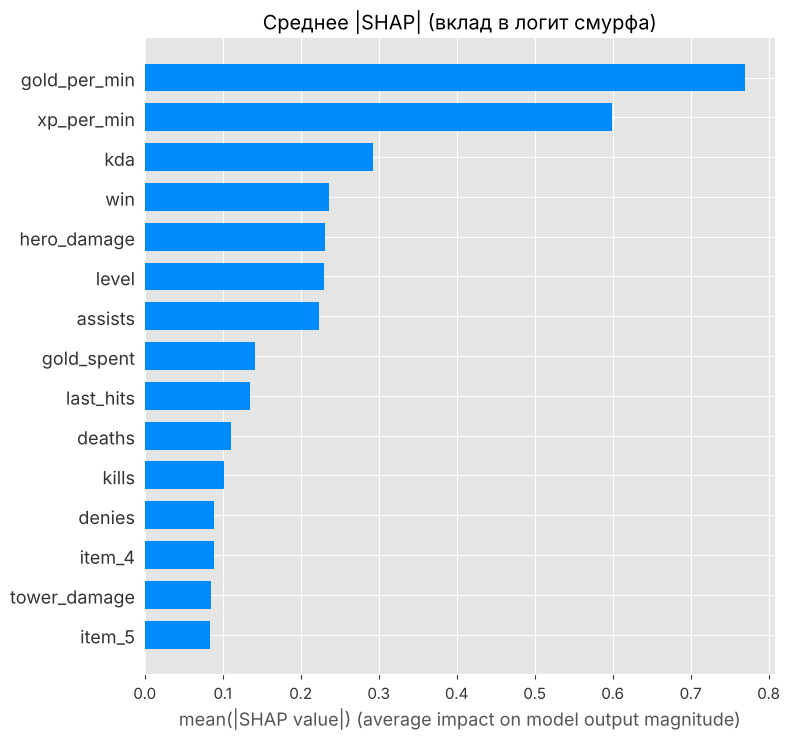

In [12]:
# 7.1 Глобальная важность (среднее |SHAP|)
shap.summary_plot(sv, Xs, plot_type="bar", show=False, max_display=15)
plt.title("Среднее |SHAP| (вклад в логит смурфа)"); plt.tight_layout(); plt.show()

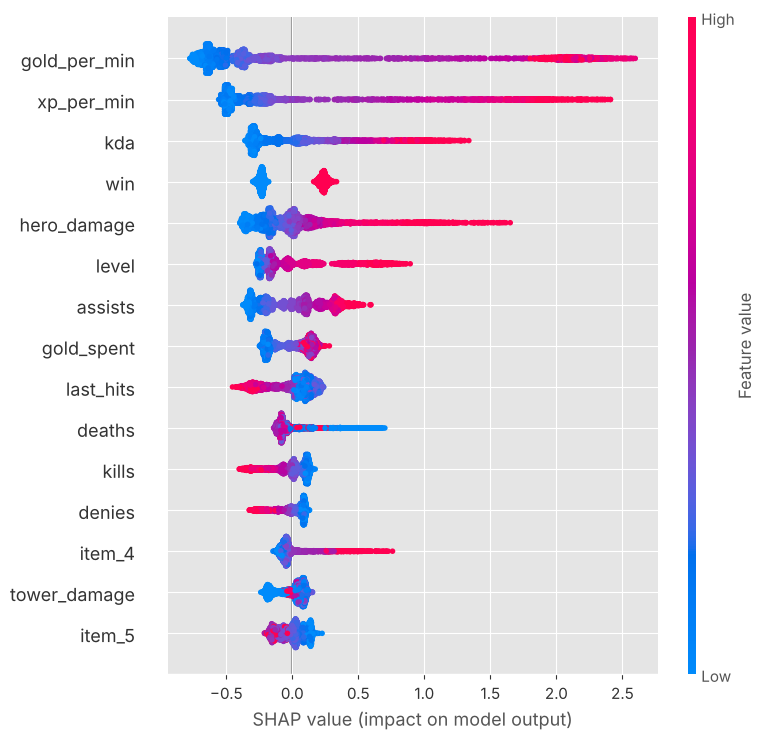

In [13]:
# 7.2 Beeswarm: направление влияния. Цвет = значение признака, ось X = сдвиг прогноза
shap.summary_plot(sv, Xs, show=False, max_display=15)
plt.tight_layout(); plt.show()

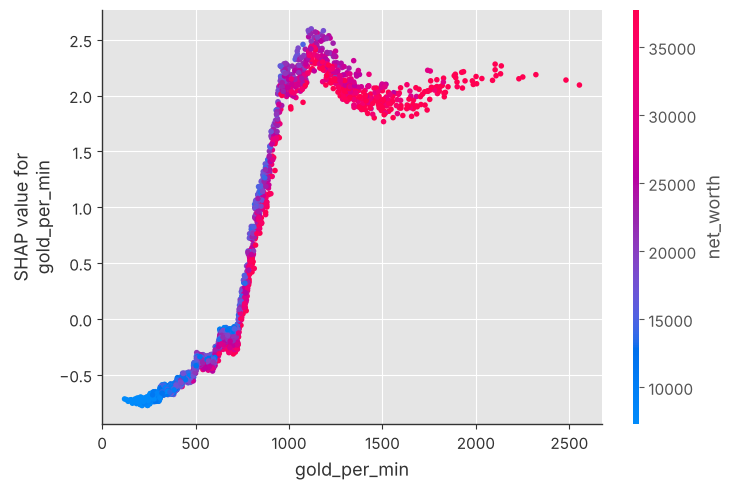

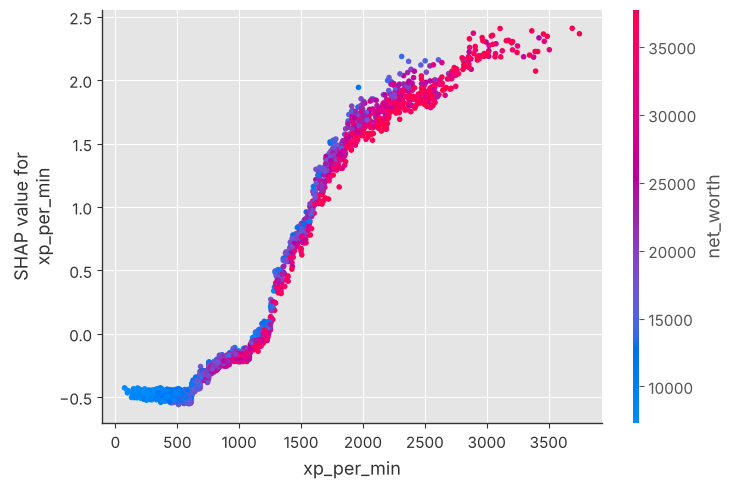

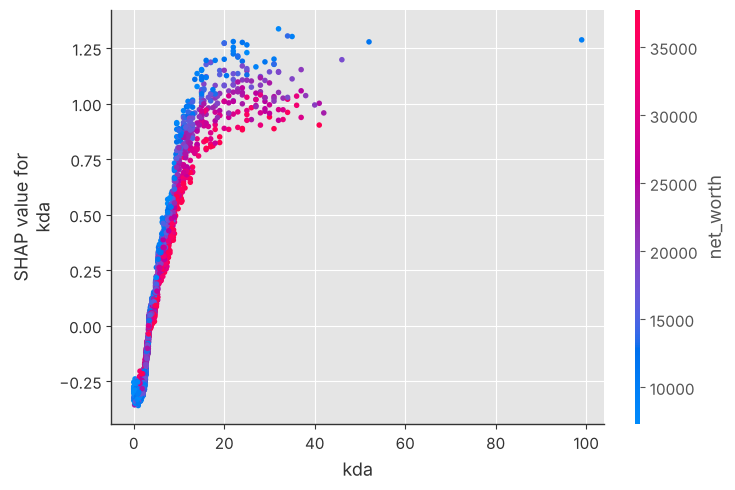

,mean|SHAP|
gold_per_min,0.769
xp_per_min,0.599
kda,0.292
win,0.236
hero_damage,0.232
level,0.229
assists,0.223
gold_spent,0.141
last_hits,0.134
deaths,0.110


In [14]:
# 7.3 Зависимость от топ-3 признаков
top = pd.Series(np.abs(sv).mean(0), index=Xs.columns).sort_values(ascending=False)
for f in top.index[:3]:
    shap.dependence_plot(f, sv, Xs, show=False)
    plt.tight_layout(); plt.show()
top.head(10).round(3).to_frame("mean|SHAP|")

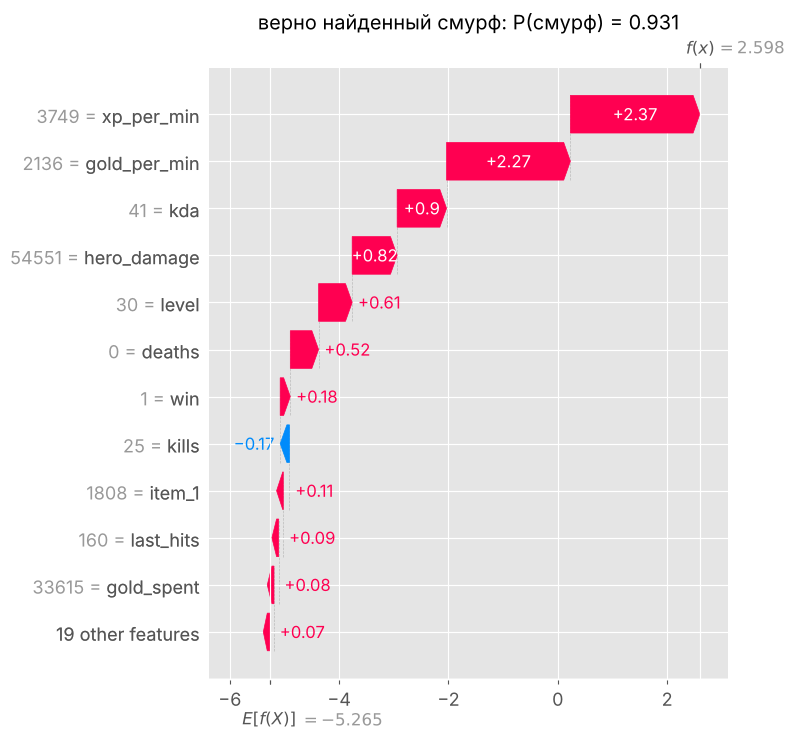

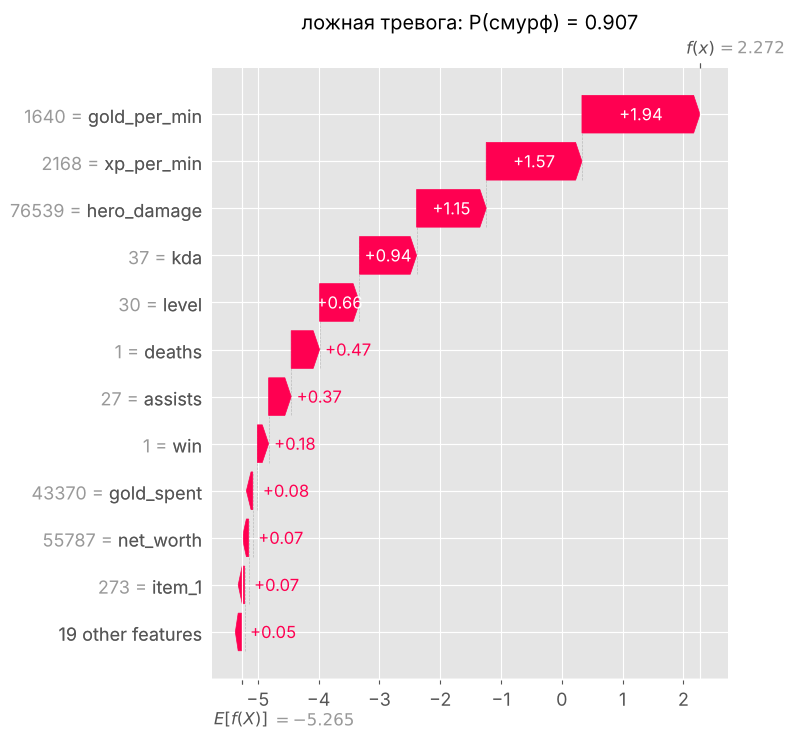

In [15]:
# 7.4 Разбор отдельных прогнозов: самый уверенный верный смурф и самая уверенная ложная тревога
Xte_r = Xte.reset_index(drop=True); yte_r = yte.reset_index(drop=True)
cases = {}
tp = np.where((yte_r == 1) & (pte >= out["thr"]))[0]
fp = np.where((yte_r == 0) & (pte >= out["thr"]))[0]
if len(tp): cases["верно найденный смурф"] = tp[np.argmax(pte[tp])]
if len(fp): cases["ложная тревога"] = fp[np.argmax(pte[fp])]

for title, i in cases.items():
    s1, b1 = catboost_shap(model, Xte_r.iloc[[i]])
    exp = shap.Explanation(values=s1[0], base_values=b1[0], data=Xte_r.iloc[i].to_numpy(),
                           feature_names=list(Xte_r.columns))
    shap.plots.waterfall(exp, max_display=12, show=False)
    plt.title(f"{title}: P(смурф) = {pte[i]:.3f}"); plt.tight_layout(); plt.show()

## 8. Сравнение конфигураций

Показывает, сколько метрики зависят от того, что видит модель. Если в `no_label_inputs` качество близко к случайному, значит почти весь сигнал в `full_raw` — это восстановление правила разметки по его входам.

In [16]:
grid = {
    "full_raw / без ранга":            dict(feature_set="full_raw"),
    "full_raw / с рангом":             dict(feature_set="full_raw", use_rank_features=True),
    "no_label_inputs / без ранга":     dict(feature_set="no_label_inputs"),
    "full_raw / unranked как 0":       dict(feature_set="full_raw", unranked="keep_as_negative"),
}
rows = {}
for name, over in grid.items():
    rows[name] = run({**CFG, **over}, verbose=False)["metrics"]
pd.DataFrame(rows).T.round(4)

,f1,precision,recall,roc_auc,pr_auc,best_iter,thr,n_test,n_test_pos
full_raw / без ранга,0.4138,0.3871,0.4444,0.9635,0.3872,59.0,0.18,8336.0,162.0
full_raw / с рангом,0.5606,0.4976,0.6420,0.9801,0.6031,75.0,0.22,8336.0,162.0
no_label_inputs / без ранга,0.1769,0.1250,0.3025,0.8439,0.1010,204.0,0.07,8336.0,162.0
full_raw / unranked как 0,0.2078,0.2092,0.2065,0.9742,0.1860,111.0,0.18,25615.0,155.0


## 9. (Опционально) Сверка с прежней разметкой

Проверяет, что новая разметка при «глобальных» эталонах совпадает со старой. Расхождения при train-only эталонах ожидаемы и невелики.

In [17]:
OLD = CFG["csv_path"]
if os.path.exists(OLD):
    old = pd.read_csv(OLD, usecols=["match_id", "player_slot", "smurf", "perf_z"])
    d = engineer(load_raw({**CFG, "source": "csv"}))
    d = d[d["rank_known"]]
    lab_all = SmurfLabeler(CFG["smurf_z"], CFG["smurf_max_tier"]).fit(d)   # эталоны по ВСЕМ данным, как раньше
    new = lab_all.transform(d)[["match_id", "player_slot", "smurf", "perf_z"]]
    m = new.merge(old, on=["match_id", "player_slot"], suffixes=("_new", "_old"))
    print("строк сравнено:", len(m), "| совпадение smurf: %.4f" % (m.smurf_new == m.smurf_old).mean(),
          "| max|Δperf_z|: %.2e" % (m.perf_z_new - m.perf_z_old).abs().max())

строк сравнено: 41673 | совпадение smurf: 1.0000 | max|Δperf_z|: 4.44e-16
